# Jour 4 - NLP avec TF-IDF
On transforme le synopsis (`overview`) en vecteurs numériques.

In [2]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
%matplotlib inline
from src.features.build_features import load_features
import src.nlp.tfidf as T

df = load_features()
genres = df['genres'].tolist()
print(df.shape)

(2000, 49)


## 1. Valeurs manquantes et nettoyage du texte

In [3]:
raw = T.build_text(df)          # NaN -> chaîne vide
clean = T.clean_series(raw)
print('Synopsis vides après nettoyage :', (clean == '').sum())
pd.DataFrame({'avant': raw.head(3).values, 'après': clean.head(3).values})

Synopsis vides après nettoyage : 0


,avant,après
0,Princess Leia is captured and held hostage by ...,princess leia is captured and held hostage by ...
1,"Nemo, an adventurous young clownfish, is unexp...",nemo an adventurous young clownfish is unexpec...
2,A man with a low IQ has accomplished great thi...,a man with a low iq has accomplished great thi...


In [4]:
# longueur des textes (mots)
pd.DataFrame({'avant': raw.str.split().str.len(), 'après': clean.str.split().str.len()}).describe().round(1)

,avant,après
count,2000.0,2000.0
mean,45.6,46.1
std,20.1,20.2
min,8.0,8.0
25%,29.0,30.0
50%,42.0,42.0
75%,58.0,59.0
max,137.0,141.0


## 2. Un premier TfidfVectorizer
`max_features=5000`, `ngram_range=(1,2)`.

In [5]:
vec = T.make_vectorizer(5000, (1, 2))
X = vec.fit_transform(clean)
print('Dimensions :', X.shape)
T.matrix_stats(X)

Dimensions : (2000, 5000)


{'n_docs': 2000,
 'vocab_size': 5000,
 'nnz': 41608,
 'sparsity_pct': 99.58,
 'nnz_per_doc': 20.8,
 'size_mb': 0.51}

In [6]:
# Les 15 premiers termes du vocabulaire et le vecteur d'un film
terms = vec.get_feature_names_out()
print(terms[:15])
i = 0
print(df.loc[i, 'title'])
T.top_terms_for_doc(vec, X, i, 8)

['aang' 'aaron' 'abandoned' 'abandoning' 'abduct' 'abducted' 'abigail'
 'abilities' 'ability' 'able' 'aboard' 'abruptly' 'absolutely' 'absurd'
 'abusive']
Star Wars


empire             0.328327
princess           0.299924
galactic empire    0.205343
luke skywalker     0.205343
skywalker          0.198992
imperial           0.198992
galactic           0.198992
luke               0.198992
Name: tfidf, dtype: float64

## 3. Expériences `max_features` x `ngram_range`
La cohérence mesure si les voisins d'un film partagent ses genres (les genres servent à évaluer, pas d'entrée).

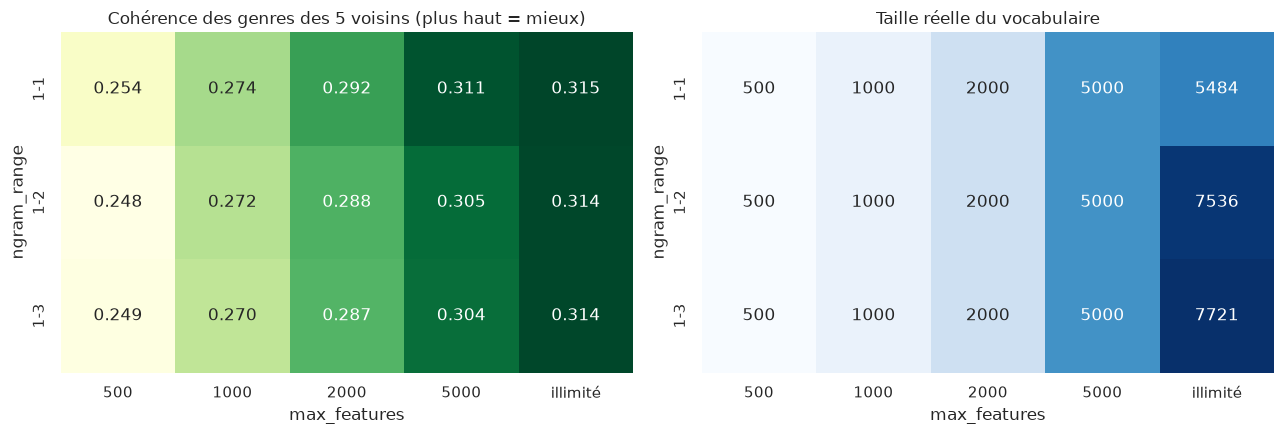

,ngram_min,ngram_max,max_features,vocab_size,nnz_per_doc,sparsity_pct,size_mb,genre_coherence,fit_seconds
0,1,1,500,500,9.3,98.13,0.23,0.2540,0.10
1,1,1,1000,1000,12.3,98.77,0.30,0.2743,0.06
2,1,1,2000,2000,15.6,99.22,0.38,0.2922,0.06
3,1,1,5000,5000,20.0,99.60,0.49,0.3111,0.06
4,1,1,<NA>,5484,20.5,99.63,0.50,0.3145,0.06
5,1,2,500,500,9.4,98.11,0.23,0.2483,0.17
6,1,2,1000,1000,12.4,98.76,0.31,0.2715,0.16
7,1,2,2000,2000,15.9,99.20,0.39,0.2878,0.17
8,1,2,5000,5000,20.8,99.58,0.51,0.3050,0.18
9,1,2,<NA>,7536,23.3,99.69,0.57,0.3138,0.14


In [7]:
exp = T.run_experiments(clean, genres)
T.plot_experiments(exp, show=True)
exp

In [8]:
print('Hasard :', round(T.random_baseline(genres), 3))
T.select_best(exp)

Hasard : 0.153


(5000, (1, 1))

## 4. Termes représentatifs

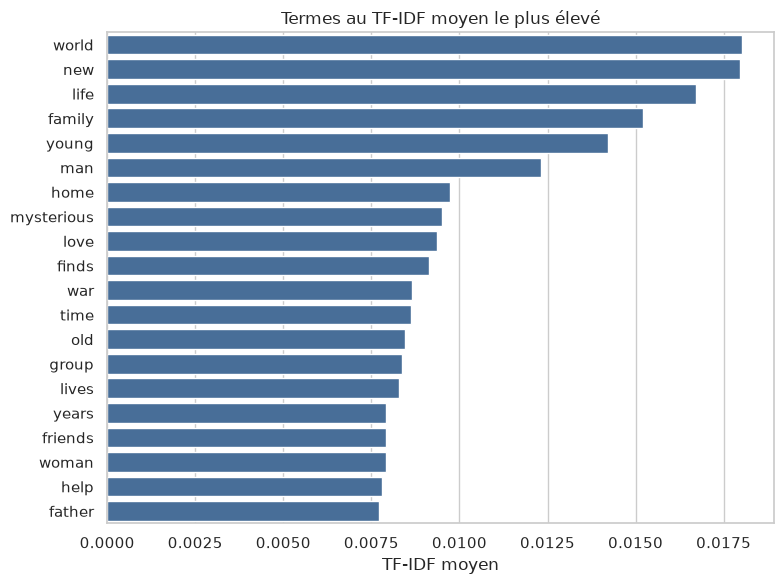

In [9]:
mf, ng = T.select_best(exp)
vec = T.make_vectorizer(mf, ng)
X = vec.fit_transform(clean).tocsr()
top = T.top_terms_global(vec, X, 20)
T.plot_top_terms(top, show=True)

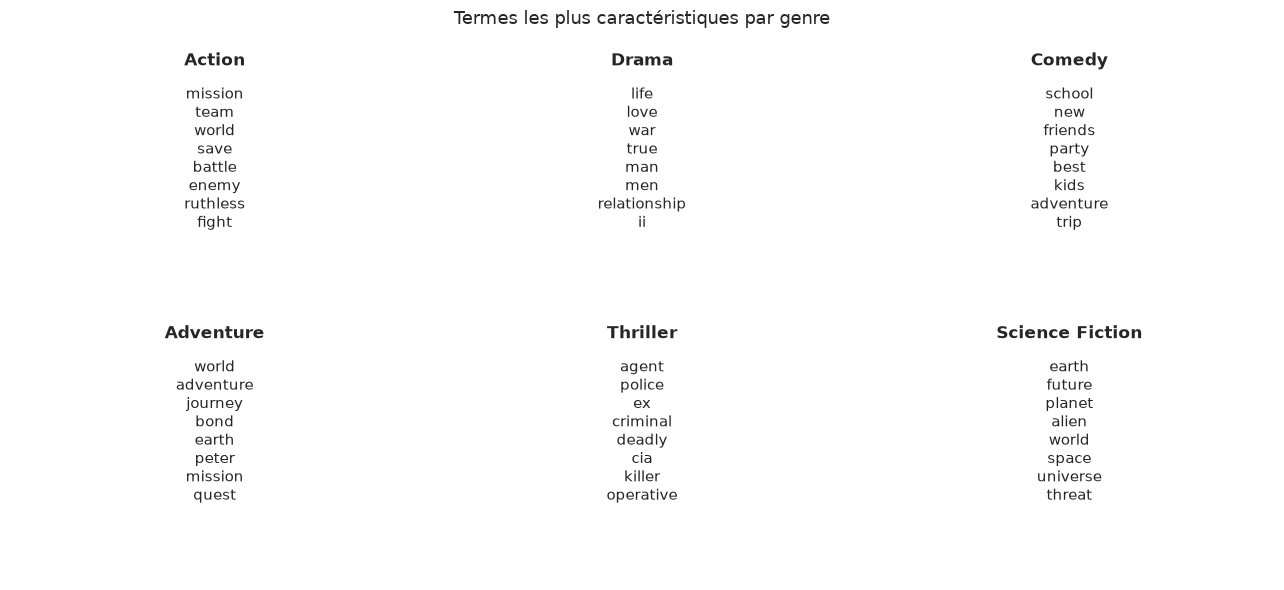

In [10]:
top_genres = pd.Series([g for l in genres for g in l]).value_counts().head(6).index.tolist()
by_genre = T.top_terms_by_genre(vec, X, genres, top_genres)
T.plot_terms_by_genre(by_genre, show=True)

## 5. Sauvegarde complète
(ou `python src/nlp/tfidf.py`)

In [11]:
info = T.run_tfidf()
T.print_summary(info)


Configuration retenue : max_features=5000, ngram_range=(1, 1)
Matrice : 2000 x 5000 | creuse à 99.6 % | 20.0 termes/film | 0.49 Mo
Cohérence des genres : 0.311 (hasard 0.153)
Top termes : world, new, life, family, young, man, home, mysterious, love, finds
  Action          : mission, team, world, save, battle, enemy, ruthless, fight
  Drama           : life, love, war, true, man, men, relationship, ii
  Comedy          : school, new, friends, party, best, kids, adventure, trip
  Adventure       : world, adventure, journey, bond, earth, peter, mission, quest
  Thriller        : agent, police, ex, criminal, deadly, cia, killer, operative
  Science Fiction : earth, future, planet, alien, world, space, universe, threat

Rapport : /home/iamjustwliya/Movie_Intelligence/reports/tfidf_report.md
Vectoriseur : /home/iamjustwliya/Movie_Intelligence/models/tfidf_vectorizer.joblib
Matrice : /home/iamjustwliya/Movie_Intelligence/data/features/tfidf_matrix.npz
